In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("netflix_titles.csv.zip")

In [3]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
df.shape

(8807, 12)

In [5]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [7]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [8]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df)) * 100
})
missing

,Missing Values,Percentage
show_id,0,0.000000
type,0,0.000000
title,0,0.000000
director,2634,29.908028
cast,825,9.367549
country,831,9.435676
date_added,10,0.113546
release_year,0,0.000000
rating,4,0.045418
duration,3,0.034064


In [9]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [10]:
df["type"].value_counts()

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

In [11]:
#normalize=True converts those counts into percentage.assert
type_percentage = df["type"].value_counts(normalize=True) * 100
type_percentage

type
Movie      69.615079
TV Show    30.384921
Name: proportion, dtype: float64

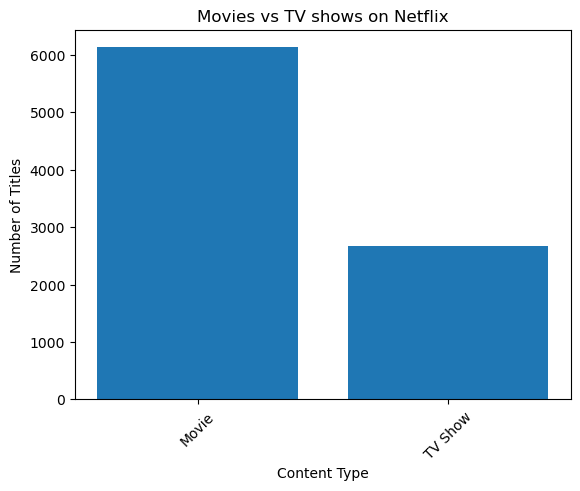

In [12]:
import matplotlib.pyplot as plt
type_counts = df["type"].value_counts()
plt.bar(type_counts.index, type_counts.values)

plt.title("Movies vs TV shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.show()

In [13]:
release_year_counts = df["release_year"].value_counts().sort_index()
release_year_counts

release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, Length: 74, dtype: int64

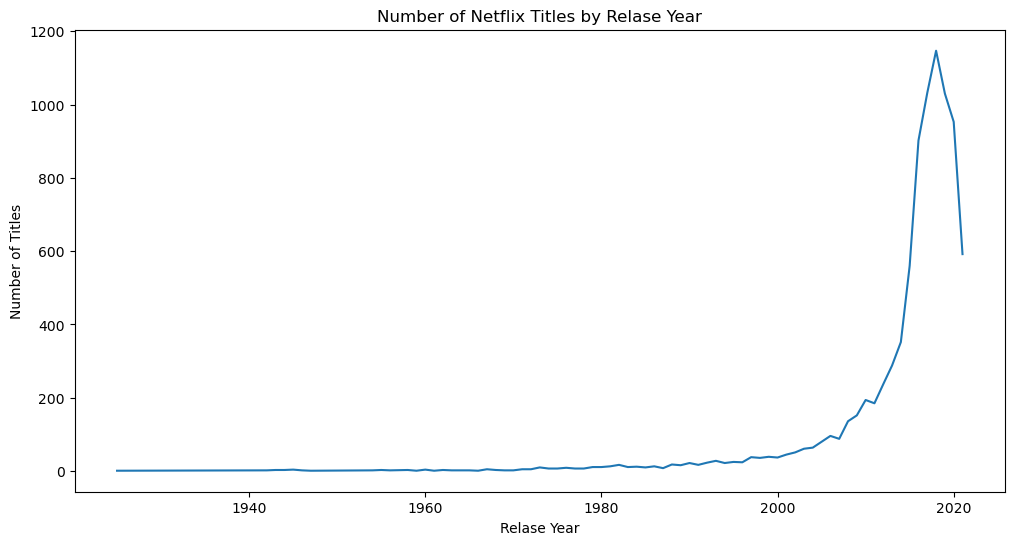

In [14]:
plt.figure(figsize=(12,6))
plt.plot(release_year_counts.index, release_year_counts.values)

plt.title("Number of Netflix Titles by Relase Year")
plt.xlabel("Relase Year")
plt.ylabel("Number of Titles")

plt.show()

In [16]:
top_release_years = release_year_counts.nlargest(10)
top_release_years

release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902
2021     592
2015     560
2014     352
2013     288
2012     237
Name: count, dtype: int64

In [17]:
type_by_year = pd.crosstab(df["release_year"], df["type"])
type_by_year

type,Movie,TV Show
release_year,,
1925,0,1
1942,2,0
1943,3,0
1944,3,0
1945,3,1
...,...,...
2017,767,265
2018,767,380
2019,633,397


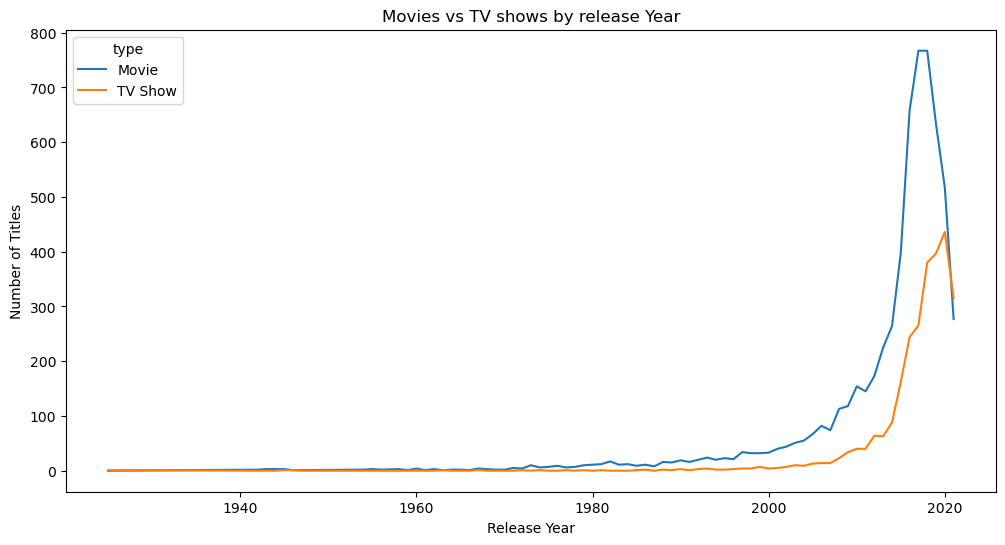

In [18]:
type_by_year.plot(figsize=(12, 6))

plt.title("Movies vs TV shows by release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.show()

In [19]:
df["rating"].value_counts()

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64

In [20]:
rating_percentage = df["rating"].value_counts(normalize=True) * 100
rating_percentage

rating
TV-MA       36.430762
TV-14       24.537090
TV-PG        9.803476
R            9.076451
PG-13        5.566284
TV-Y7        3.794161
TV-Y         3.487447
PG           3.260252
TV-G         2.499148
NR           0.908781
G            0.465750
TV-Y7-FV     0.068159
NC-17        0.034079
UR           0.034079
74 min       0.011360
84 min       0.011360
66 min       0.011360
Name: proportion, dtype: float64

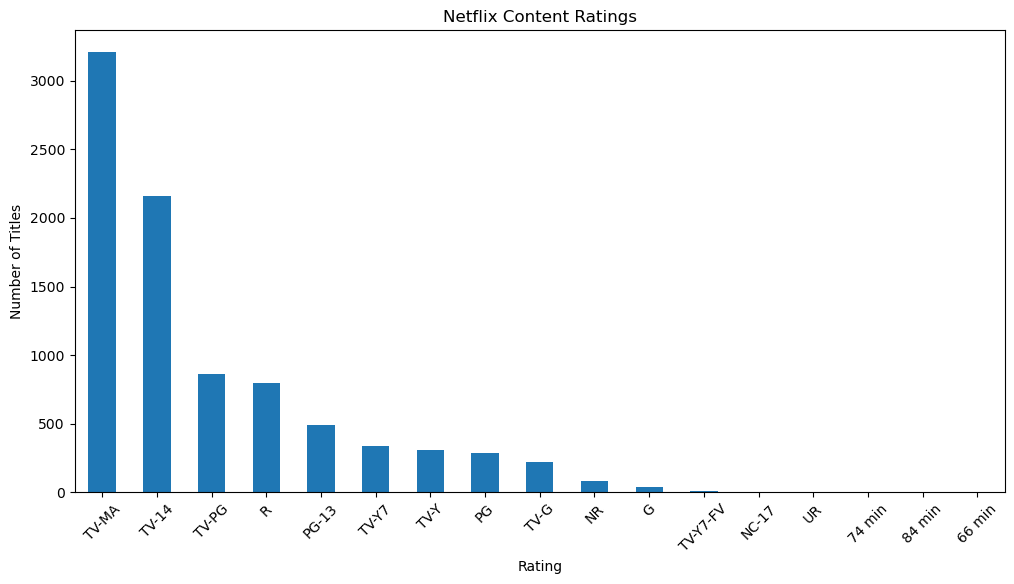

In [21]:
rating_counts = df["rating"].value_counts()

rating_counts.plot(kind="bar", figsize=(12, 6))

plt.title("Netflix Content Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.show()

In [22]:
df[df["rating"].isin(["74 min", "84 min", "66 min"])]

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
5541,s5542,Movie,Louis C.K. 2017,Louis C.K.,Louis C.K.,United States,"April 4, 2017",2017,74 min,NaN,Movies,"Louis C.K. muses on religion, eternal love, gi..."
5794,s5795,Movie,Louis C.K.: Hilarious,Louis C.K.,Louis C.K.,United States,"September 16, 2016",2010,84 min,NaN,Movies,Emmy-winning comedy writer Louis C.K. brings h...
5813,s5814,Movie,Louis C.K.: Live at the Comedy Store,Louis C.K.,Louis C.K.,United States,"August 15, 2016",2015,66 min,NaN,Movies,The comic puts his trademark hilarious/thought...


In [23]:
df.loc[df["rating"].isin(["74 min", "84 min", "66 min"]), "duration"] = df["rating"]

In [24]:
df.loc[df["rating"].isin(["74 min", "84 min", "66 min"]), "rating"] = None

In [25]:
df[df["title"].str.contains("Louis C.K.", na=False)][
    ["title", "rating", "duration"]
]

,title,rating,duration
5541,Louis C.K. 2017,None,74 min
5794,Louis C.K.: Hilarious,None,84 min
5813,Louis C.K.: Live at the Comedy Store,None,66 min


In [26]:
movies = df[df["type"] == "Movie"]

In [27]:
movies["duration"].head(10)

0      90 min
6      91 min
7     125 min
9     104 min
12    127 min
13     91 min
16     67 min
18     94 min
22    161 min
23     61 min
Name: duration, dtype: object

In [28]:
movies["duration"].nunique()

205

In [29]:
movies["duration_minutes"] = movies["duration"].str.replace(" min", "").astype(float)

C:\Users\HP\AppData\Local\Temp\ipykernel_14920\887021208.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  movies["duration_minutes"] = movies["duration"].str.replace(" min", "").astype(float)


In [30]:
movies[["duration", "duration_minutes"]].head(10)

,duration,duration_minutes
0,90 min,90.0
6,91 min,91.0
7,125 min,125.0
9,104 min,104.0
12,127 min,127.0
13,91 min,91.0
16,67 min,67.0
18,94 min,94.0
22,161 min,161.0
23,61 min,61.0


In [31]:
movies["duration_minutes"].describe()

count    6131.000000
mean       99.564998
std        28.289504
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_minutes, dtype: float64

In [32]:
movies["duration_minutes"].median()

98.0

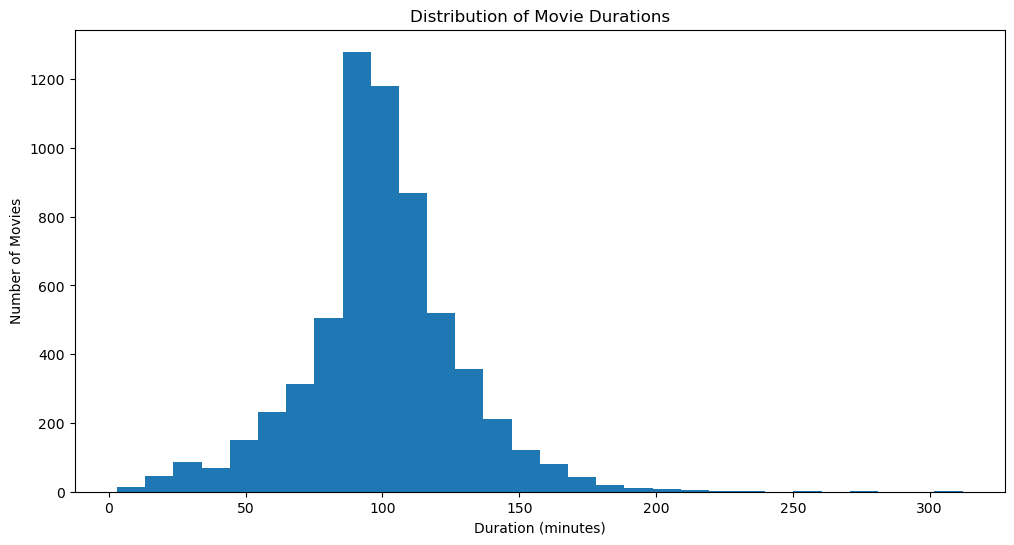

In [35]:
plt.figure(figsize=(12, 6))

plt.hist(movies["duration_minutes"], bins=30)

plt.title("Distribution of Movie Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")

plt.show()

In [36]:
#duration = number of seasons
tv_shows = df[df["type"] == "TV Show"]
tv_shows["duration"].value_counts().head(10)

duration
1 Season      1793
2 Seasons      425
3 Seasons      199
4 Seasons       95
5 Seasons       65
6 Seasons       33
7 Seasons       23
8 Seasons       17
9 Seasons        9
10 Seasons       7
Name: count, dtype: int64

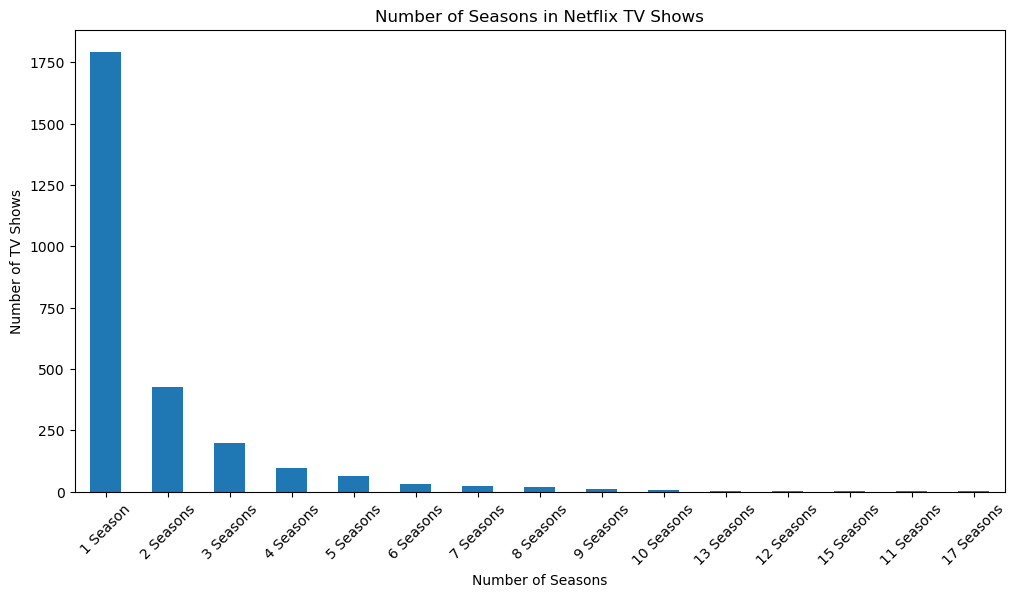

In [37]:
tv_duration_counts = tv_shows["duration"].value_counts()

tv_duration_counts.plot(kind="bar", figsize=(12, 6))

plt.title("Number of Seasons in Netflix TV Shows")
plt.xlabel("Number of Seasons")
plt.ylabel("Number of TV Shows")
plt.xticks(rotation=45)

plt.show()

In [39]:
df["listed_in"].head(10)

0                                        Documentaries
1      International TV Shows, TV Dramas, TV Mysteries
2    Crime TV Shows, International TV Shows, TV Act...
3                               Docuseries, Reality TV
4    International TV Shows, Romantic TV Shows, TV ...
5                   TV Dramas, TV Horror, TV Mysteries
6                             Children & Family Movies
7     Dramas, Independent Movies, International Movies
8                         British TV Shows, Reality TV
9                                     Comedies, Dramas
Name: listed_in, dtype: object

In [41]:
genres = df["listed_in"].str.split(", ")
genres.head(10)

0                                      [Documentaries]
1    [International TV Shows, TV Dramas, TV Mysteries]
2    [Crime TV Shows, International TV Shows, TV Ac...
3                             [Docuseries, Reality TV]
4    [International TV Shows, Romantic TV Shows, TV...
5                 [TV Dramas, TV Horror, TV Mysteries]
6                           [Children & Family Movies]
7    [Dramas, Independent Movies, International Mov...
8                       [British TV Shows, Reality TV]
9                                   [Comedies, Dramas]
Name: listed_in, dtype: object

In [42]:
genre_counts = genres.explode().value_counts()
genre_counts.head(10)

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

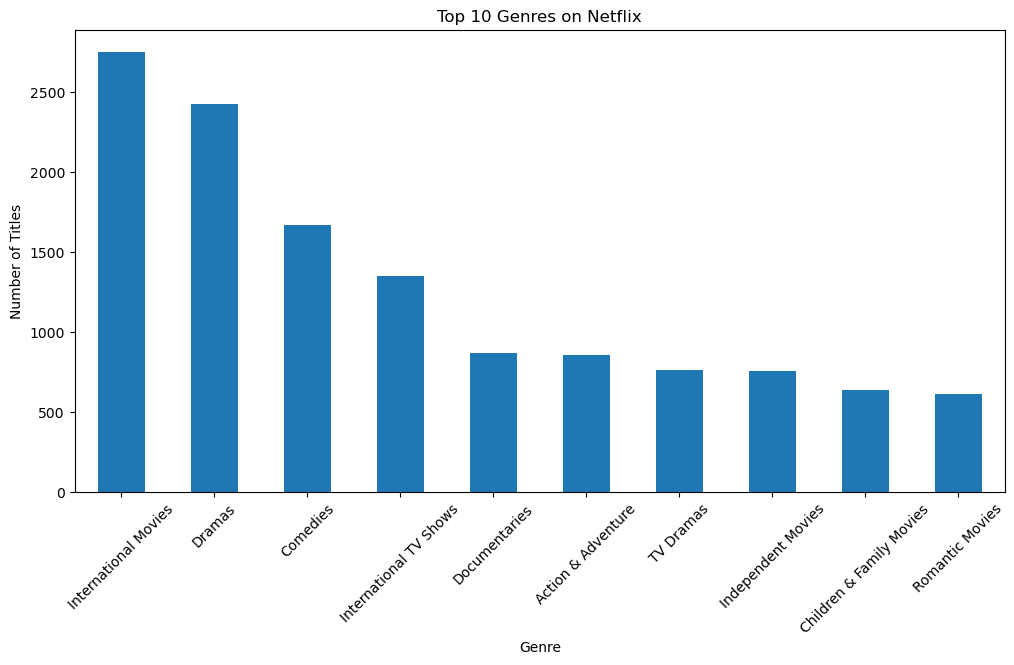

In [43]:
top_genres = genre_counts.head(10)

top_genres.plot(kind="bar", figsize=(12, 6))

plt.title("Top 10 Genres on Netflix")
plt.xlabel("Genre")
plt.ylabel("Number of Titles")
plt.xticks(rotation = 45)

plt.show()

In [44]:
df["country"].head(10)

0                                        United States
1                                         South Africa
2                                                  NaN
3                                                  NaN
4                                                India
5                                                  NaN
6                                                  NaN
7    United States, Ghana, Burkina Faso, United Kin...
8                                       United Kingdom
9                                        United States
Name: country, dtype: object

In [45]:
countries = df["country"].dropna().str.split(", ")
countries.head()

0                                      [United States]
1                                       [South Africa]
4                                              [India]
7    [United States, Ghana, Burkina Faso, United Ki...
8                                     [United Kingdom]
Name: country, dtype: object

In [46]:
country_counts = countries.explode().value_counts()

country_counts.head(10)

country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64

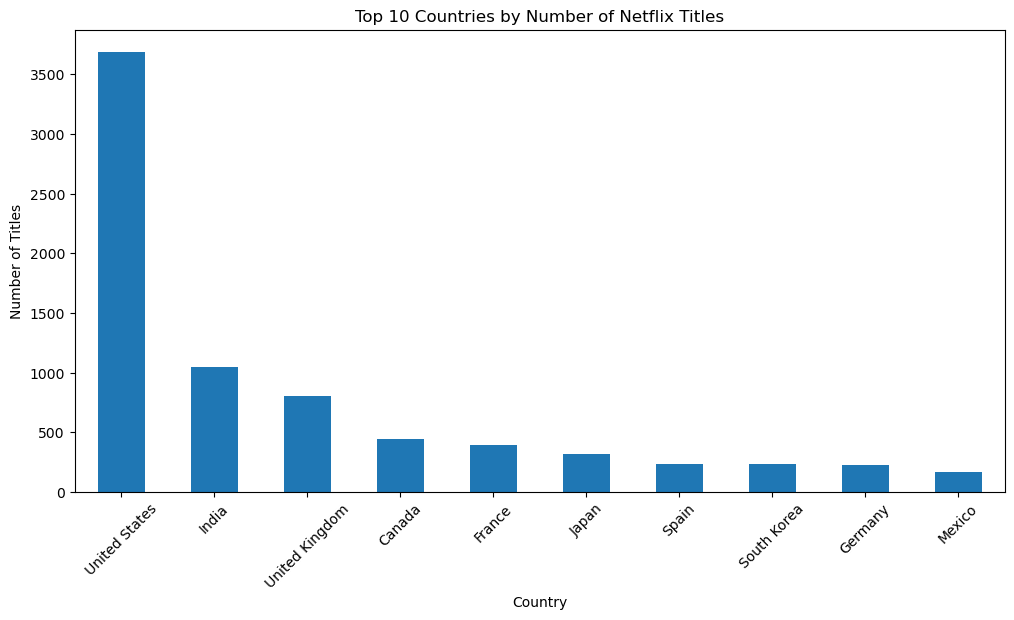

In [47]:
top_countries = country_counts.head(10)

top_countries.plot(
    kind="bar",
    figsize=(12, 6)
)
plt.title("Top 10 Countries by Number of Netflix Titles")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.show()

In [56]:
df["date_added"].head(10)

0    September 25, 2021
1    September 24, 2021
2    September 24, 2021
3    September 24, 2021
4    September 24, 2021
5    September 24, 2021
6    September 24, 2021
7    September 24, 2021
8    September 24, 2021
9    September 24, 2021
Name: date_added, dtype: object

In [59]:
#convert date_added to datetime
#str.strip->removes extra space
df["date_added"] = df["date_added"].str.strip()

In [60]:
df["date_added"] = pd.to_datetime(
    df["date_added"],
    format="mixed"
)

In [61]:
df["date_added"].head(10)

0   2021-09-25
1   2021-09-24
2   2021-09-24
3   2021-09-24
4   2021-09-24
5   2021-09-24
6   2021-09-24
7   2021-09-24
8   2021-09-24
9   2021-09-24
Name: date_added, dtype: datetime64[ns]

In [62]:
df["date_added_year"] = df["date_added"].dt.year

In [63]:
content_added_by_year = df["date_added_year"].value_counts().sort_index()
content_added_by_year

date_added_year
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     429
2017.0    1188
2018.0    1649
2019.0    2016
2020.0    1879
2021.0    1498
Name: count, dtype: int64

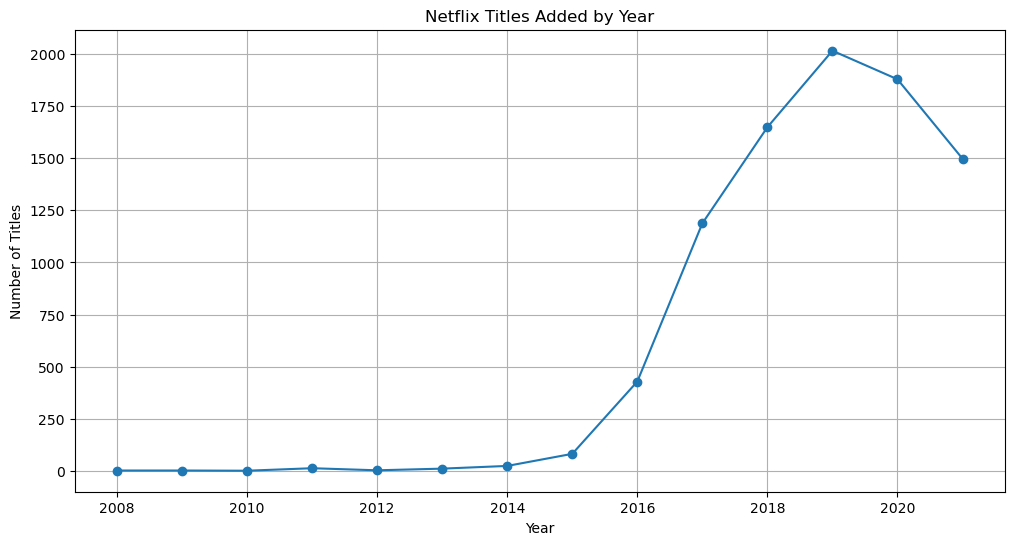

In [67]:
plt.figure(figsize=(12, 6))

plt.plot(
    content_added_by_year.index,
    content_added_by_year.values,
    marker="o"
)

plt.title("Netflix Titles Added by Year")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.grid(True)
plt.show()

In [70]:
content_type_by_year = pd.crosstab(
    df["date_added_year"],
    df["type"]
)
content_type_by_year

type,Movie,TV Show
date_added_year,,
2008.0,1,1
2009.0,2,0
2010.0,1,0
2011.0,13,0
2012.0,3,0
2013.0,6,5
2014.0,19,5
2015.0,56,26
2016.0,253,176


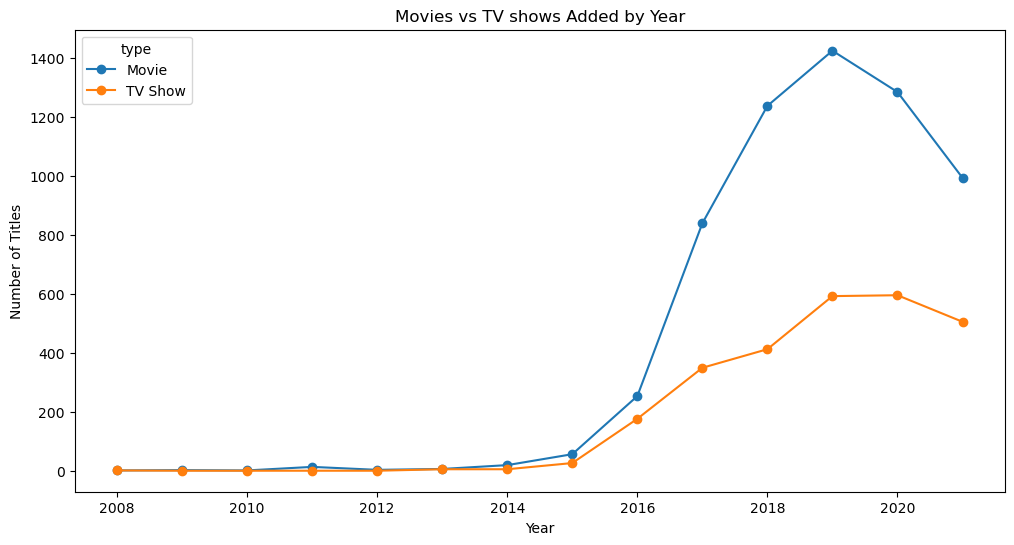

In [71]:
content_type_by_year.plot(
    figsize=(12, 6),
    marker="o"
)

plt.title("Movies vs TV shows Added by Year")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.show()

In [72]:
director_counts = df["director"].value_counts()

director_counts

director
Rajiv Chilaka              19
Raúl Campos, Jan Suter     18
Suhas Kadav                16
Marcus Raboy               16
Jay Karas                  14
                           ..
James Brown                 1
Ivona Juka                  1
Mu Chu                      1
Chandra Prakash Dwivedi     1
Majid Al Ansari             1
Name: count, Length: 4528, dtype: int64

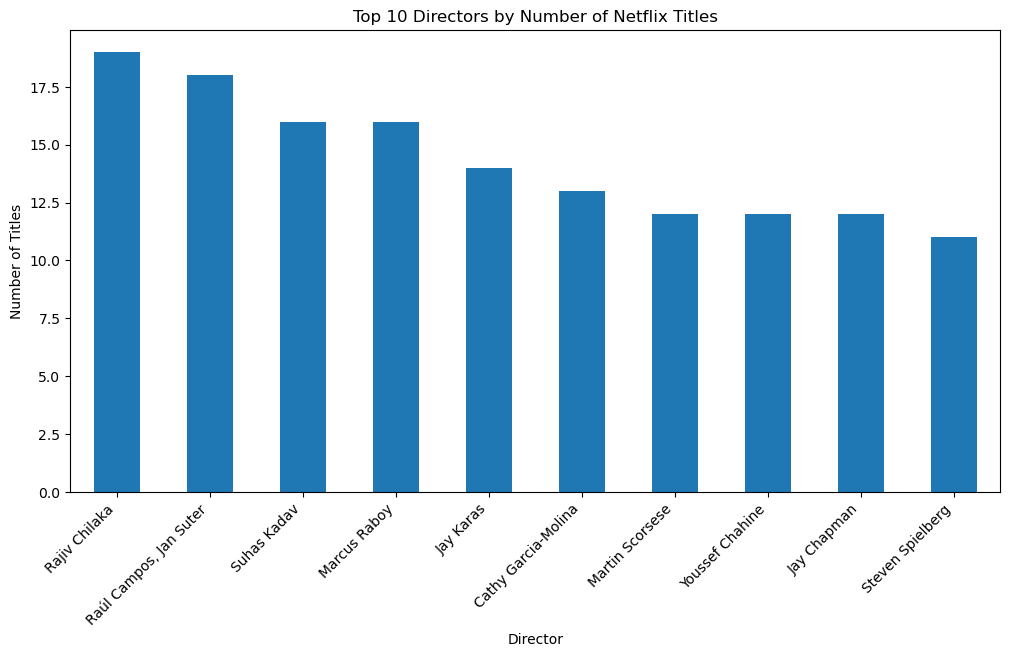

In [75]:
top_directors = director_counts.head(10)

top_directors.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Top 10 Directors by Number of Netflix Titles")
plt.xlabel("Director")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.show()

In [76]:
df["cast"].head(10)

0                                                  NaN
1    Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...
2    Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...
3                                                  NaN
4    Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...
5    Kate Siegel, Zach Gilford, Hamish Linklater, H...
6    Vanessa Hudgens, Kimiko Glenn, James Marsden, ...
7    Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...
8    Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...
9    Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...
Name: cast, dtype: object

In [77]:
cast = df["cast"].dropna().str.split(", ")

In [78]:
cast.head()

1    [Ama Qamata, Khosi Ngema, Gail Mabalane, Thaba...
2    [Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nab...
4    [Mayur More, Jitendra Kumar, Ranjan Raj, Alam ...
5    [Kate Siegel, Zach Gilford, Hamish Linklater, ...
6    [Vanessa Hudgens, Kimiko Glenn, James Marsden,...
Name: cast, dtype: object

In [79]:
cast_counts = cast.explode().value_counts()

cast_counts.head(10)

cast
Anupam Kher         43
Shah Rukh Khan      35
Julie Tejwani       33
Takahiro Sakurai    32
Naseeruddin Shah    32
Rupa Bhimani        31
Om Puri             30
Akshay Kumar        30
Yuki Kaji           29
Amitabh Bachchan    28
Name: count, dtype: int64

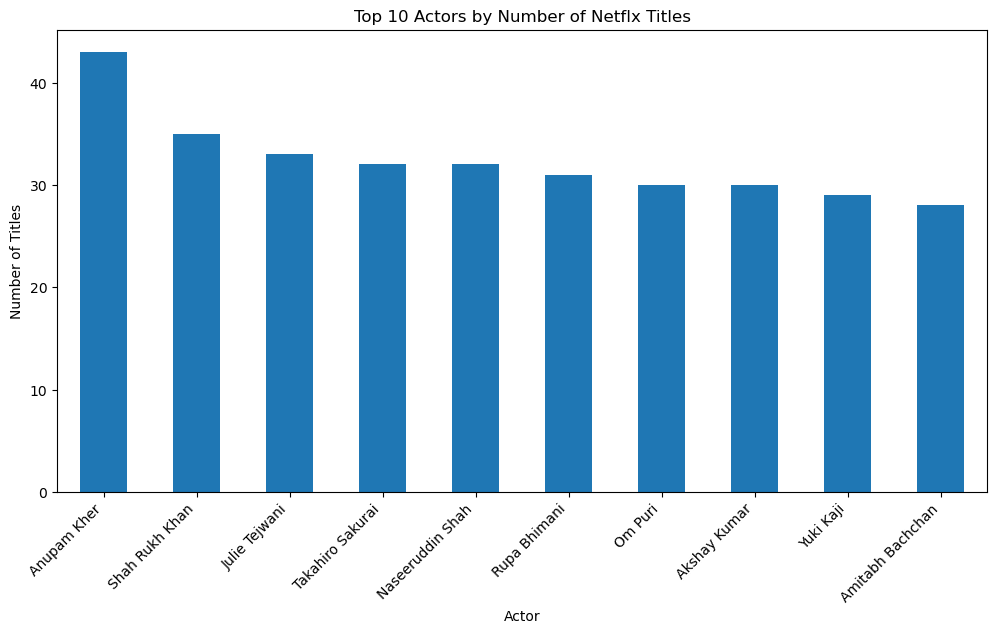

In [82]:
top_actors = cast_counts.head(10)

top_actors.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Top 10 Actors by Number of Netflx Titles")
plt.xlabel("Actor")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.show()

In [83]:
rating_by_type = pd.crosstab(df["rating"], df["type"])
rating_by_type

type,Movie,TV Show
rating,,
G,41,0
NC-17,3,0
NR,75,5
PG,287,0
PG-13,490,0
R,797,2
TV-14,1427,733
TV-G,126,94
TV-MA,2062,1145


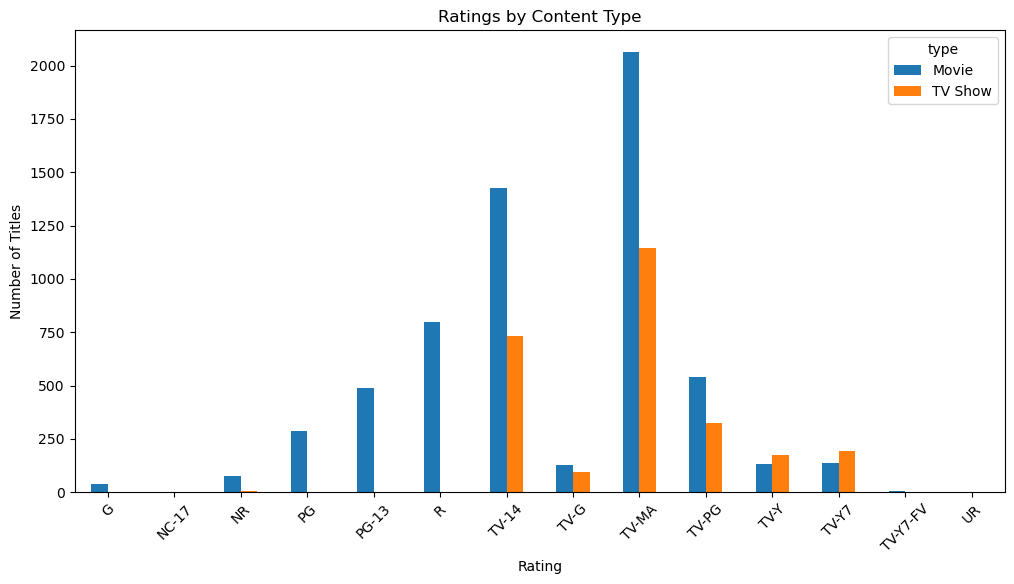

In [84]:
rating_by_type.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Ratings by Content Type")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()

# Netflix Movies & TV Shows — Exploratory Data Analysis

## 1. Introduction

## 2. Import Libraries

## 3. Load Dataset

## 4. Understand the Dataset

## 5. Missing Values Analysis

## 6. Movies vs TV Shows

## 7. Release Year Analysis

## 8. Content Ratings

## 9. Movie Duration Analysis

## 10. TV Show Season Analysis

## 11. Genre Analysis

## 12. Country Analysis

## 13. Netflix Content Added Over Time

## 14. Director Analysis

## 15. Actor Analysis

## 16. Key Findings

## 17. Conclusion